<div style="text-align: center;">
    <a href="https://www.hi-paris.fr/">
        <img border="0" src="https://www.hi-paris.fr/wp-content/uploads/2020/09/logo-hi-paris-retina.png" width="25%"></a>
    <a href="https://www.dataia.eu/">
        <img border="0" src="https://github.com/ramp-kits/template-kit/raw/main/img/DATAIA-h.png" width="70%"></a>
</div>

# &lt;Challenge name&gt;: starting kit

<i>&lt;Team members (affiliation)&gt;</i>

> **How to fill this template.** Replace every *italic prompt* and `<placeholder>`
> by your own content. The code cells run on the template's stand-in data
> (breast cancer, binary classification): adapt them to yours. Commit the
> notebook **executed, with its outputs**, so it reads on GitHub.

## TL;DR

| | |
|---|---|
| **Task** | *&lt;one line: what is predicted from what&gt;* |
| **Data** | *&lt;source, size in independent units (patients, sites...)&gt;* |
| **Metric** | *&lt;metric, higher/lower is better&gt;* |
| **Evaluation** | *&lt;CV scheme and folds, test sets: unit held out, public/private sizes&gt;* |
| **Baselines** | *&lt;Dummy floor score&gt;* vs *&lt;sample submission score&gt;* (CV and public) |

## 1. Data and question

*Answer each point in a few sentences.*

- **Where does the data come from?** *Who collected it, how, and under which
  license. Can it be redistributed?*
- **What is the question?** *What is predicted, from which inputs.*
- **Why does it matter?** *Who would use such a model, and for which decision.
  What would a good score change?*
- **Can this data answer it?** *Point to the EDA and baseline evidence below.*

## 2. Exploratory data analysis

*Show what is in the data, and the structure that decides the evaluation:
groups (patients, sites, subjects), time, duplicates, class balance. Give
every figure a title and axis labels, and follow it with a one-line
takeaway.*

The data is built by the benchmark's `Real` dataset: `benchopt prepare`
writes it to `benchmark/data/real`, and the test labels to
`benchmark/data/reference` (re-run with `--force` if you deleted them). We
load exactly what the solvers receive: the training data `X, y` and the test
sets `X_test`, without their labels.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from benchopt.benchmark import Benchmark
pd.set_option('display.max_columns', 20)

!benchopt prepare benchmark -d Real

(Real, params), = Benchmark('benchmark').check_dataset_patterns(['Real'])
data = Real.get_instance(**params).get_data()
X, y, X_test = data['X'], data['y'], data['X_test']
y_test = {name: pd.read_csv(f'benchmark/data/reference/{name}.csv')['target']
          for name in X_test}
print(f"train: {X.shape}", *(f"{k}: {Xt.shape}" for k, Xt in X_test.items()))
X.head()

Preparing datasets for benchmark 'template_codabench'
No seed was specified. Selected global seed: 0
Preparing Real ... done (cached)
Summary: 1/1 datasets ready.


train: (341, 30) public: (114, 30) private: (114, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,0.1060,0.05502,...,11.92,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905
1,19.81,22.15,130.00,1260.0,0.09831,0.10270,0.14790,0.09498,0.1582,0.05395,...,27.32,30.88,186.80,2398.0,0.15120,0.31500,0.5372,0.23880,0.2768,0.07615
2,16.30,15.70,104.70,819.8,0.09427,0.06712,0.05526,0.04563,0.1711,0.05657,...,17.32,17.76,109.80,928.2,0.13540,0.13610,0.1947,0.13570,0.2300,0.07230
3,12.86,13.32,82.82,504.8,0.11340,0.08834,0.03800,0.03400,0.1543,0.06476,...,14.04,21.08,92.80,599.5,0.15470,0.22310,0.1791,0.11550,0.2382,0.08553
4,13.64,16.34,87.21,571.8,0.07685,0.06059,0.01857,0.01723,0.1353,0.05953,...,14.67,23.19,96.08,656.7,0.10890,0.15820,0.1050,0.08586,0.2346,0.08025


### Target and features

In [2]:
pd.DataFrame({name: labels.value_counts(normalize=True)
              for name, labels in {'train': y, **y_test}.items()})

,train,public,private
target,,,
1,0.621701,0.675439,0.596491
0,0.378299,0.324561,0.403509


*Takeaway: e.g. "the classes are imbalanced (63/37) and the balance is the
same in every split".*

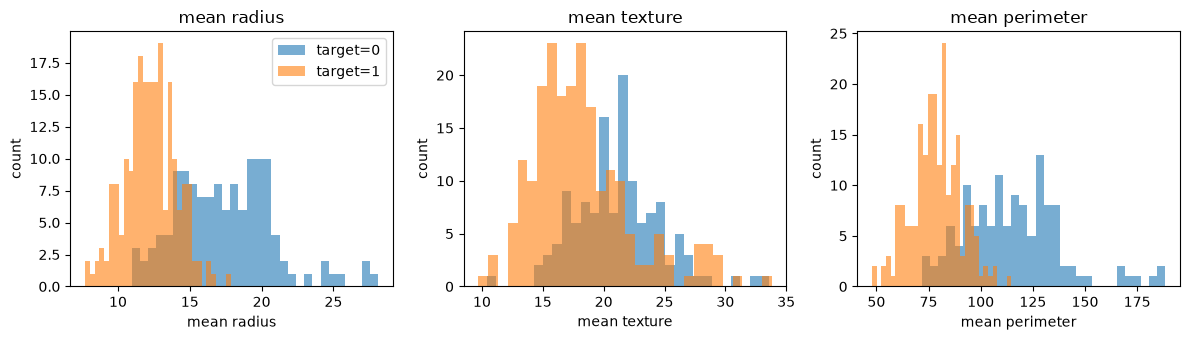

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, X.columns[:3]):
    for label in sorted(y.unique()):
        ax.hist(X.loc[y == label, col], bins=30, alpha=.6,
                label=f'target={label}')
    ax.set(title=col, xlabel=col, ylabel='count')
axes[0].legend()
fig.tight_layout()

*Takeaway: e.g. "several features separate the classes well: the task is
learnable".*

*Add what your data needs: missing values, feature types, correlations,
time trends, groups...*

## 3. Evaluation

Submissions are trained and scored with cross-validation (CV) on the
training data, one fold per benchopt repetition: `benchmark/objective.py`
defines the folds (`cv`) and the metric (`evaluate_result`). Each fold's model
also predicts the test sets cut in `benchmark/datasets/real.py` (`prepare`),
and the scoring program scores these predictions against the hidden labels.
Every score is averaged over the folds. The public test set is shown live on
the leaderboard. The private one is hidden and gives the final ranking.

### 3.1 Metric

*Why this metric and not the obvious alternative (e.g. accuracy vs balanced
accuracy vs AUC under class imbalance)? What is the cost of each kind of
error for the use case of section 1?*

### 3.2 Split

*Which unit is held out, in the CV folds and in the test sets (rows,
patients, sites, time periods), and why it matches how the model would be
used. Link it to the structure found in the EDA. Give the size of each split
in that unit.*

### 3.3 Leakage checks

*Show, with code, that the test sets are independent from the training set
for the generalization the leaderboard measures. Adapt the checks below to
your split.*

In [4]:
# No sample appears both in train and in a test set.
train_rows = set(map(tuple, X.round(8).values))
for name, Xt in X_test.items():
    n_dup = sum(tuple(r) in train_rows for r in Xt.round(8).values)
    print(f"{name}: {n_dup} rows duplicated from train")

# For a group split, assert that no group is on both sides, e.g.:
# assert not set(groups_train) & set(groups_public)

public: 0 rows duplicated from train
private: 0 rows duplicated from train


In [5]:
# Adversarial validation: can a model tell train from test? AUC ~ 0.5 means
# the test sets look like the train set (no shift a model could exploit).
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

for name, Xt in X_test.items():
    X_adv = pd.concat([X, Xt])
    y_adv = np.r_[np.zeros(len(X)), np.ones(len(Xt))]
    auc = cross_val_score(RandomForestClassifier(random_state=0), X_adv, y_adv,
                          cv=5, scoring='roc_auc').mean()
    print(f"train vs {name}: AUC = {auc:.2f}")

train vs public: AUC = 0.46


train vs private: AUC = 0.50


*Takeaway. If you split by group or time, a shift between train and test
can be expected and wanted: say which shift the leaderboard measures.*

### 3.4 Baselines and their spread over the folds

`benchopt run` trains and scores the solvers exactly as the platform does,
once per fold (`-r 5`). `Dummy` is the floor and `RandomForest` the sample
submission. The sample submission must clearly beat the floor (else the task
is not learnable from this data) and leave room above it (else it is
trivial).

The spread over the folds tells how large a leaderboard gap must be to mean
something. The CV, public and private scores of a baseline should agree
within it.

In [6]:
!benchopt run benchmark -d Real -s RandomForest -s Dummy -r 5 \
    --no-plot --no-html --no-display --output outputs/starting_kit.parquet

from benchopt.results import read_results
from sklearn.metrics import accuracy_score

results = read_results('outputs/starting_kit.parquet')
# The test scores, computed per fold as the scoring program does.
for name, labels in y_test.items():
    results[f'accuracy_{name}'] = [
        accuracy_score(labels, pred) for pred in results[f'objective_{name}_pred']]
results = results.rename(columns={'objective_accuracy_cv': 'accuracy_cv'})
scores = ['accuracy_cv', *(f'accuracy_{name}' for name in y_test)]
results.groupby('solver_name')[scores].agg(['mean', 'std']).round(3)

Benchopt is running!


Loading objective, datasets and solvers...

 done.


Real                                                                            
  |--classification-accuracy                                                    
No seed was specified. Selected global seed: 0


    |--RandomForest: done                                                       


    |--Dummy: done                                                              


Saving result in: outputs/starting_kit.parquet                                  


accuracy_cv        accuracy_public        accuracy_private       
                    mean    std            mean    std             mean    std
solver_name                                                                   
Dummy              0.622  0.006           0.675  0.000            0.596  0.000
RandomForest       0.956  0.018           0.954  0.017            0.937  0.007

*Takeaway: e.g. "the sample submission beats the floor by 0.3, and gaps below
0.02 (the spread over the folds) are noise".*

## 4. Submission format

A submission is a single `submission.py` defining `class Solver(CompetSolver)`.
Its `get_model` method returns the untrained model, and an optional `fit`
method trains it (by default `model.fit(X_train, y_train)`). The platform
trains the model once per fold, then calls `model.predict(X)` on the
held-out part of the fold and on the test sets. See
`benchmark/benchmark_utils/base_solver.py` for the full contract. The sample
submission:

In [7]:
!cat benchmark/solvers/random-forest.py

"""Sample submission: the starting point participants copy and improve.

A submission is a benchopt solver: a ``submission.py`` defining
``class Solver(CompetSolver)`` with a ``get_model`` method (and optionally
``fit``). See ``benchmark/benchmark_utils/base_solver.py`` for the contract.
The bundle ships this file as the Codabench sample submission.

Copy it to a folder of your own as ``submission.py`` and run it exactly as
the platform does::

    benchopt run benchmark -d Simulated -s my_submission/submission.py
    # real data
    benchopt prepare benchmark -d Real
    benchopt run benchmark -d Real -s my_submission/submission.py
"""

from sklearn.ensemble import RandomForestClassifier

from benchmark_utils.base_solver import CompetSolver


class Solver(CompetSolver):

    name = "RandomForest"

    def get_model(self, meta):
        return RandomForestClassifier(random_state=0)


## 5. Test and submit

Copy the sample to `my_submission/submission.py`, improve it, and run it
locally exactly as the server does. The CV score you get here is the CV
column of the leaderboard.

```bash
benchopt run benchmark -d Real -s my_submission/submission.py -r 5
```

To submit, zip the folder containing your `submission.py` (and any file it
reads) and upload it on the competition page.